# Starter: State of the Agent Internet: September 2026

Mirror of Hugging Face csoai/state-of-the-agent-internet

Dataset: [nicktempleman/csoai-state-of-the-agent-internet](https://www.kaggle.com/datasets/nicktempleman/csoai-state-of-the-agent-internet) · Publisher: [Council of AI](https://councilof.ai) (CSOAI Ltd) · Hugging Face twin: [csoai/state-of-the-agent-internet](https://huggingface.co/datasets/csoai/state-of-the-agent-internet)

This notebook loads the files, shows shape and schema, and gives a few summary statistics and plots. It does not compute new measurements. Measurement is not certification; for the current board state use https://councilof.ai/api/gspc.

## 1. Locate the files

In [1]:
import os, json, glob
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATASET_REF = "nicktempleman/csoai-state-of-the-agent-internet"
SLUG = DATASET_REF.split("/")[1]
PREFERRED = 'data/numbers-2026-09.parquet'   # file chosen when this notebook was prepared; any tabular file works

def find_data_dir():
    env = os.environ.get("DATA_DIR")
    if env and Path(env).is_dir():
        return Path(env)
    for c in [Path("/kaggle/input") / SLUG,
              Path("/kaggle/input/datasets") / DATASET_REF]:
        if c.is_dir():
            return c
    root = Path("/kaggle/input")
    if root.is_dir():  # mount layouts differ between Kaggle images; search for the slug
        for p in root.rglob(SLUG):
            if p.is_dir():
                return p
    raise FileNotFoundError("Attach " + DATASET_REF + " as notebook input, or set DATA_DIR")

DATA_DIR = find_data_dir()
files = sorted(p for p in DATA_DIR.rglob("*") if p.is_file())
inventory = pd.DataFrame({
    "file": [str(p.relative_to(DATA_DIR)) for p in files],
    "ext": [p.suffix.lower() or "(none)" for p in files],
    "bytes": [p.stat().st_size for p in files],
})
print(DATA_DIR, "|", len(inventory), "files,", inventory.bytes.sum(), "bytes")
inventory.groupby("ext").agg(files=("file", "count"), bytes=("bytes", "sum")).sort_values("files", ascending=False)

/Users/nicholas/.claude-science/orgs/afd8d9ac-019f-4b20-9510-5402272d5585/workspaces/560da339-f920-41b7-8102-c57af3fc4b18/kg/localdata/csoai-state-of-the-agent-internet | 7 files, 82136 bytes


          files  bytes
ext                   
.json         4  60966
.parquet      2  20014
.jsonl        1   1156

## 2. Load a table
The loader reads Parquet, CSV, JSONL, a JSON list of records, or the largest record list inside a JSON object.

In [2]:
def load_table(path: Path, max_rows=200_000):
    """Return a DataFrame for csv/tsv/parquet/jsonl, or for a JSON list / JSON object holding a list of records."""
    ext = path.suffix.lower()
    if ext == ".parquet":
        return pd.read_parquet(path)
    if ext in (".csv", ".tsv"):
        return pd.read_csv(path, sep="\t" if ext == ".tsv" else ",", nrows=max_rows)
    if ext == ".jsonl":
        rows = []
        with open(path, encoding="utf-8") as fh:
            for i, line in enumerate(fh):
                if i >= max_rows:
                    break
                line = line.strip()
                if line:
                    try:
                        rows.append(json.loads(line))
                    except json.JSONDecodeError:
                        pass
        rows = [r for r in rows if isinstance(r, dict)]
        return pd.json_normalize(rows, max_level=0) if rows else None
    if ext == ".json":
        doc = json.loads(path.read_text(encoding="utf-8"))
        if isinstance(doc, list) and doc and all(isinstance(r, dict) for r in doc[:50]):
            return pd.json_normalize(doc, max_level=0)
        if isinstance(doc, dict):
            lists = {k: v for k, v in doc.items() if isinstance(v, list) and v and all(isinstance(r, dict) for r in v[:50])}
            if lists:
                key = max(lists, key=lambda k: len(lists[k]))
                print("records taken from key:", key)
                return pd.json_normalize(lists[key], max_level=0)
    return None

candidates = [DATA_DIR / PREFERRED] if PREFERRED and (DATA_DIR / PREFERRED).exists() else []
candidates += [p for p in files if p.suffix.lower() in (".parquet", ".csv", ".tsv", ".jsonl", ".json")]
df, source = None, None
for p in candidates:
    try:
        t = load_table(p)
    except Exception as exc:  # keep going: some JSON files are documents, not tables
        print("skip", p.name, type(exc).__name__)
        continue
    if t is not None and len(t.columns) > 1 and len(t) > 0:
        df, source = t, p
        break
assert df is not None, "no tabular file found"
print("table:", source.relative_to(DATA_DIR), "| shape:", df.shape)
df.head()

table: data/numbers-2026-09.parquet | shape: (174, 10)


                      key                                                                    what  value_int value_text           source                                                          recompute                                              source_path                                                     source_sha256                                                                          source_public_copy source_board_signature
0         a2a.0x_VERIFIED                                                   0.x cards that verify        5.0       None  a2a_v0_1_1_rows                                  canonicalisation_rule x sig_state  cp-fix-20260926/a2a-corr/out/data/cards.v0.1.1.jsonl.gz  93f9865008531a9cb5c44bc8c8d32a1bf1dc775c4e3ec9880128f13c6ab2791c  https://huggingface.co/datasets/csoai/a2a-card-census/blob/main/data/cards.v0.1.1.jsonl.gz                   None
1            a2a.0x_cards  signed cards judged under 0.x rules (no canonicalisation step defined)        8.0       N

## 3. Schema

In [3]:
def kind(s):
    v = s.dropna()
    if v.empty: return "empty"
    return type(v.iloc[0]).__name__

schema = pd.DataFrame({"dtype": df.dtypes.astype(str),
                       "python_type": [kind(df[c]) for c in df.columns],
                       "non_null": df.notna().sum(),
                       "null_share": df.isna().mean().round(3)})
schema

                          dtype python_type  non_null  null_share
key                      object         str       174       0.000
what                     object         str       174       0.000
value_int               float64     float64       172       0.011
value_text               object         str         2       0.989
source                   object         str       174       0.000
recompute                object         str       174       0.000
source_path              object         str       174       0.000
source_sha256            object         str       174       0.000
source_public_copy       object         str       132       0.241
source_board_signature   object         str        90       0.483

## 4. Summary statistics

In [4]:
scalar = df[[c for c in df.columns if df[c].map(lambda v: not isinstance(v, (list, dict))).all()]]
num = scalar.select_dtypes("number")
print("numeric columns:", list(num.columns))
display(num.describe().T) if not num.empty else print("no numeric columns")
cat_cols = [c for c in scalar.columns if c not in num.columns and 1 < scalar[c].nunique() <= 30]
for c in cat_cols[:3]:
    print("\n", c); print(scalar[c].value_counts().head(10).to_string())

numeric columns: ['value_int']

 value_text
value_text
97.2     1
17.58    1

 source
source
xl_daily                22
cp_v0_1_2_rows          22
mcp_census_v0_2_1       16
a2a_v0_1_1_rows         12
mcp_census_v0_2_rows    11
erc8004                 11
erc8004_agents_rows      9
self_parity              9
hf_spaces_rows           9
mill_batch2              8

 source_path
source_path
xl-daily/2026-09-26/xl-daily-2026-09-26.json                                  22
cp-fix-20260926/v012/rec/rows.v0.1.2.jsonl.gz                                 22
census-v0.2-2026-09-26/pub/record.v0.2.1.json                                 16
cp-fix-20260926/a2a-corr/out/data/cards.v0.1.1.jsonl.gz                       12
census-v0.2-2026-09-26/pub/results.v0.2.public.jsonl.gz                       11
stage/erc8004-agent-census/record.json                                        11
stage/erc8004-agent-census/agents.jsonl.gz                                     9
self-parity/2026-09-26/record.json          

           count          mean           std  ...    50%     75%       max
value_int  172.0  11551.244186  53031.599352  ...  139.0  2635.0  505635.0

[1 rows x 8 columns]

## 5. Plots

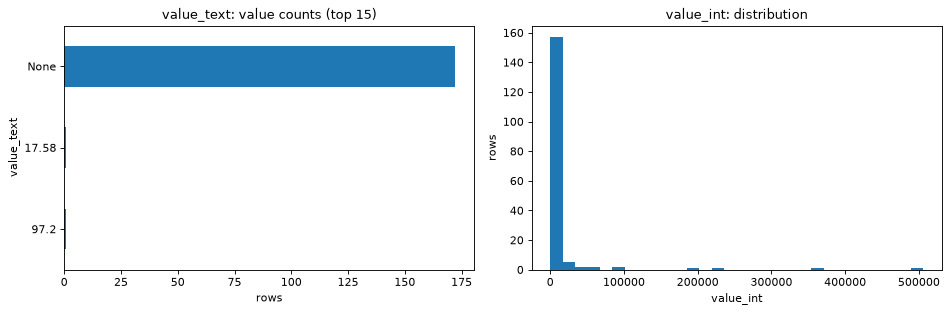

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if cat_cols:
    c = cat_cols[0]
    scalar[c].astype(str).value_counts().head(15).sort_values().plot.barh(ax=axes[0])
    axes[0].set_title(f"{c}: value counts (top 15)"); axes[0].set_xlabel("rows")
else:
    axes[0].axis("off"); axes[0].text(0.5, 0.5, "no low-cardinality column", ha="center")
if not num.empty:
    c = num.columns[num.notna().sum().argmax()]
    num[c].dropna().plot.hist(ax=axes[1], bins=30)
    axes[1].set_title(f"{c}: distribution"); axes[1].set_xlabel(c); axes[1].set_ylabel("rows")
else:
    df.notna().mean().sort_values().tail(15).plot.barh(ax=axes[1])
    axes[1].set_title("share of non-null values per column"); axes[1].set_xlabel("share of rows")
fig.tight_layout(); plt.show()

## 6. Signed records
Files ending in `.signed.json` are signed record envelopes. To verify one, open https://councilof.ai/gspc-verify/ and paste or upload the file. This notebook runs without internet access, so it only lists the envelope fields.

In [6]:
signed = [p for p in files if p.name.endswith(".signed.json")]
print(len(signed), "signed record file(s)")
for p in signed[:3]:
    doc = json.loads(p.read_text(encoding="utf-8"))
    keys = list(doc) if isinstance(doc, dict) else type(doc).__name__
    print("-", p.relative_to(DATA_DIR), "| top-level keys:", keys)

1 signed record file(s)
- 2026-09/numbers.signed.json | top-level keys: ['schema', 'payload', 'signature', 'local_verification']


## Notes
- Keep the Kaggle version number with any result; the files are a dated snapshot.
- Null means absent or not applicable, not zero.
- Dataset licence: CC-BY-4.0.